In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

#Load original csv
df = pd.read_csv("../data/raw/japan_earthquakes_2001_2018.csv")
#print(df.head())
#print(df.shape)

#Check missing values
#print(df.isnull().sum())

#Check total missing values
print(df.isnull().sum().sum())

#Check missing values in each column
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentange":(df.isnull().mean() * 100).round(2)
})

#print(missing_report)

required_columns = [
    "time",
    "latitude",
    "longitude",
    "depth",
    "mag",
    "place"
]

#Remove rows containing at least one missing value
df_cleaned = df.dropna(subset=required_columns).copy()

#Filter earthquakes geographically within Japan's approximate boundaries
df_japan = df_cleaned[
  (df_cleaned["latitude"].between(24,46)) &
  (df_cleaned["longitude"].between(122,154))
].copy()

print("\n Original records:", len(df))
print("Cleand records : ", len(df_cleaned))
print("Japan earthquake records:", len(df_japan))
print("Removed records :", len(df) - len(df_cleaned))

#Save japan's records in separate csv
df_japan.to_csv("../data/processed/cleaned_japan_earthquakes_2001_2018.csv",
index =False
 )

print("Japan earthquake dataset saved successfully")


df_japan.head()

45003

 Original records: 14092
Cleand records :  14092
Japan earthquake records: 11904
Removed records : 0
Japan earthquake dataset saved successfully


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
1,2018-11-26T23:33:50.630Z,36.0733,139.7830,48.82,4.8,mww,NaN,113.0,1.359,1.13,...,2018-11-27T16:44:22.223Z,"3km SSW of Sakai, Japan",earthquake,6.0,6.1,0.071,19.0,reviewed,us,us
2,2018-11-26T13:04:02.250Z,38.8576,141.8384,50.56,4.5,mb,NaN,145.0,1.286,0.84,...,2018-11-26T23:52:21.074Z,"26km SSE of Ofunato, Japan",earthquake,8.4,9.5,0.156,12.0,reviewed,us,us
4,2018-11-25T09:19:05.010Z,33.9500,134.4942,38.19,4.6,mb,NaN,104.0,0.558,0.61,...,2018-11-25T23:24:52.615Z,"9km SW of Komatsushima, Japan",earthquake,3.4,10.1,0.132,17.0,reviewed,us,us
6,2018-11-23T14:30:14.510Z,37.1821,141.1721,46.76,5.2,mb,NaN,140.0,0.750,0.80,...,2018-11-26T02:54:51.216Z,"29km ENE of Iwaki, Japan",earthquake,7.2,6.2,0.064,81.0,reviewed,us,us
7,2018-11-23T07:19:51.110Z,29.3424,142.3121,10.00,4.7,mb,NaN,130.0,2.241,0.76,...,2018-11-23T08:14:59.040Z,"250km N of Chichi-shima, Japan",earthquake,9.4,1.9,0.090,37.0,reviewed,us,us


## Analyze Earthquake Frequency
1. How many earthquakes occured each year?
2. How many earthquakes occured each month?
3. Which year had the highest earthquake frequency?
4. Which month had the highest earthquake frequency?

In [6]:
df_processed_jp = pd.read_csv("../data/processed/cleaned_japan_earthquakes_2001_2018.csv")
df_processed_jp.head()

df_processed_jp["time"] = pd.to_datetime(df["time"], utc = True)
df_processed_jp.head()

#Extract year and month
df_processed_jp["year"] = df_processed_jp["time"].dt.year
df_processed_jp["month"] = df_processed_jp["time"].dt.month
df_processed_jp.head()

#Count earthquakes by year
yearly_frequency = df_processed_jp.groupby("year").size()

print("=== yearly earthquake frequency ===")
print(yearly_frequency)


#Count earthquakes by month
monthly_frequency = df_processed_jp.groupby("month").size()
monthly_frequency = monthly_frequency.reindex(range(1,13), fill_value=0)

print("=== monthly earthquake frequency ===")
print(monthly_frequency)

#Highest earthquake frequency
highest_year = yearly_frequency.idxmax()
highest_year_count = yearly_frequency.max()

#Highest earthquake month
highest_month = monthly_frequency.idxmax()
highest_month_count = monthly_frequency.max()

print("=== Earthquake Frequency Summary ===")
print(f"Highest earthquake year:{highest_year}" f"({highest_year_count} earthquakes)")

print(f"Highest earthquake month:{highest_month}" f"({highest_month_count} earthquakes)")

#Group by year and month
yearly_monthly_frequency = (
    df_processed_jp.groupby(["year","month"])
                   .size()
                    .unstack(fill_value=0)
)

yearly_monthly_frequency = yearly_monthly_frequency.reindex(
    columns=range(1, 13),
    fill_value=0
)


print("=== Yearly and monthly frequency ===")
yearly_monthly_frequency.head(20)



=== yearly earthquake frequency ===
year
2005      51
2006     860
2007     655
2008     449
2009     334
2010     658
2011    3811
2012    1086
2013     724
2014     751
2015     666
2016     772
2017     523
2018     564
dtype: int64
=== monthly earthquake frequency ===
month
1      870
2      593
3     2578
4     1092
5      802
6      710
7      762
8      732
9      749
10     725
11    1126
12    1165
dtype: int64
=== Earthquake Frequency Summary ===
Highest earthquake year:2011(3811 earthquakes)
Highest earthquake month:3(2578 earthquakes)
=== Yearly and monthly frequency ===


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2005,0,0,0,0,0,0,0,0,0,0,0,51
2006,16,22,22,36,20,27,12,24,42,63,482,94
2007,168,33,64,81,37,46,39,57,28,33,34,35
2008,20,29,49,30,69,49,47,27,27,30,22,50
2009,42,21,21,48,19,23,13,37,35,31,16,28
2010,20,32,37,19,21,35,26,31,37,19,23,358
2011,153,78,1984,433,267,179,166,139,120,102,96,94
2012,105,106,155,98,89,60,102,51,45,67,51,157
2013,69,71,35,77,42,45,53,59,53,71,79,70


## Earthquake frequency visualization

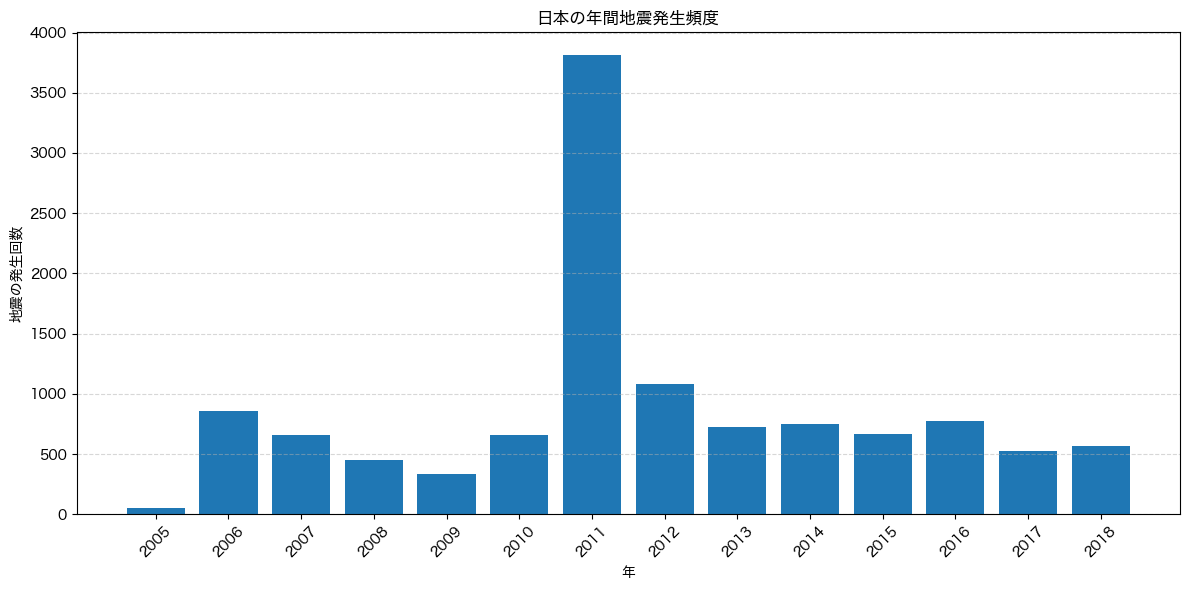

In [9]:
# Chart 1 : Yearly Earthquake Frequency
plt.rcParams["font.family"] = "Hiragino Sans"
plt.rcParams["axes.unicode_minus"] = False

plt.figure(figsize = (12,6))

plt.bar(yearly_frequency.index, yearly_frequency.values)

plt.title("日本の年間地震発生頻度")
plt.xlabel("年")
plt.ylabel("地震の発生回数")
plt.xticks(yearly_frequency.index, rotation = 45)
plt.grid(axis="y", linestyle="--", alpha = 0.5)
plt.tight_layout()
plt.savefig("../data/processed/yearly_earthquake_frequency.png")
plt.show()

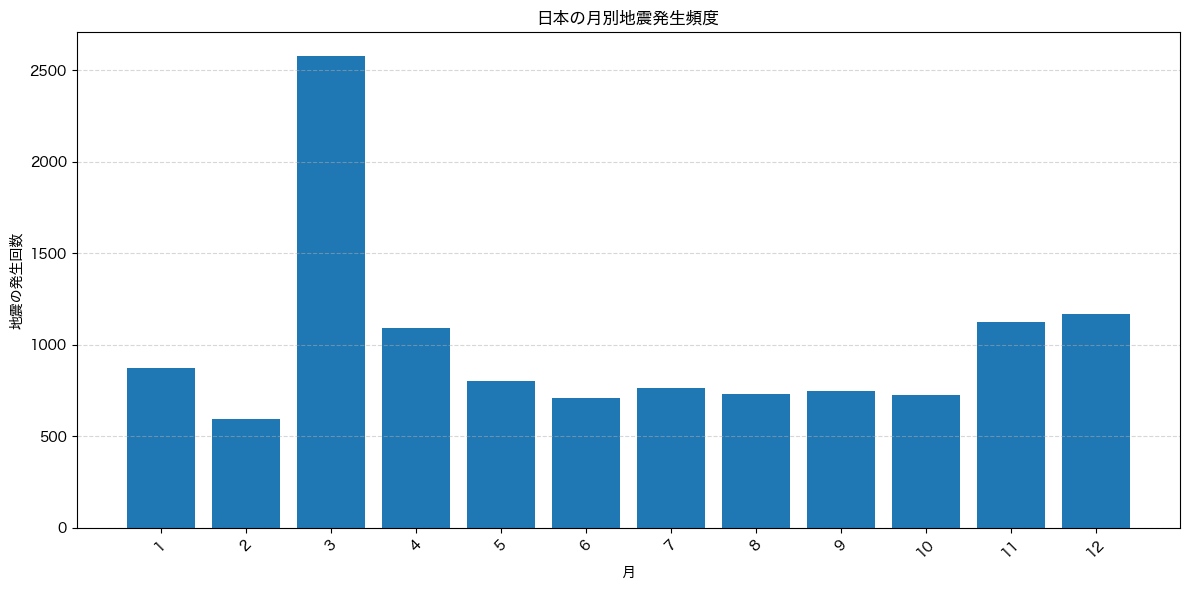

In [11]:
# Chart 2 : Monthly Earthquake Frequency

plt.figure(figsize = (12,6))

month_names = ["1","2","3","4","5","6","7","8","9","10","11","12"]
plt.bar(monthly_frequency.index, monthly_frequency.values)

plt.title("日本の月別地震発生頻度")
plt.xlabel("月")
plt.ylabel("地震の発生回数")
plt.xticks(monthly_frequency.index, rotation = 45)
plt.grid(axis="y", linestyle="--", alpha = 0.5)
plt.tight_layout()
plt.savefig("../data/processed/monthly_earthquake_frequency.png")
plt.show()

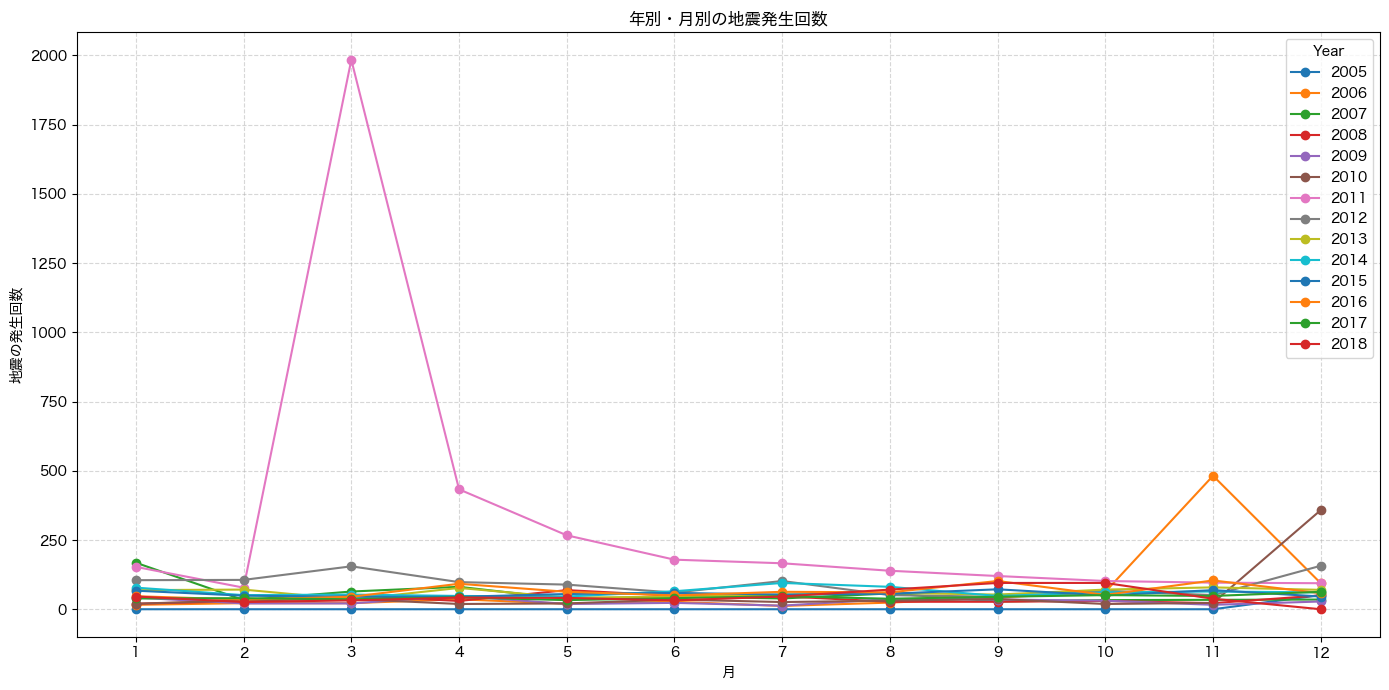

All earthquake frequency charts created successfully!


In [13]:
# Chart 3 : Yearly and monthly frequency

plt.figure(figsize=(14,7))
for year in yearly_monthly_frequency.index:
    plt.plot(month_names, yearly_monthly_frequency.loc[year], marker="o", label=str(year))

plt.title("年別・月別の地震発生回数")
plt.xlabel("月")
plt.ylabel("地震の発生回数")

plt.legend(title="Year")
plt.grid(linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../data/processed/yearly_monthly_earthquake_frequency.png")

plt.show()

print("All earthquake frequency charts created successfully!")

In [17]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

import pandas as pd
import plotly
import folium
import streamlit
import streamlit_folium

print("Pandas:", pd.__version__)
print("Plotly:", plotly.__version__)
print("Folium:", folium.__version__)
print("Streamlit:", streamlit.__version__)
print("Streamlit folium:")

Python version: 3.11.7 (main, Dec 15 2023, 12:09:04) [Clang 14.0.6 ]
Python executable: /opt/anaconda3/bin/python
Pandas: 2.1.4
Plotly: 5.9.0
Folium: 0.20.0
Streamlit: 1.30.0
Streamlit folium:
